# Argand plots: scipy_3 multi-GPU high-field eigenvalues

Loads `eigs_stepXX.npz` from
`/pscratch/sd/d/divyam/hine_runs/paper_1gpu/jacobian_high_eigs/scipy_3_n4/section_*/`.

Each file stores one largest-magnitude Ritz value (and eigenvector) for that
autoregressive step. Plots:
1. Argand plane (Re vs Im) per section, with unit circle and max-|λ| circle
2. Time series of eigenvalue radii `|λ|_max` vs AR frame (overlay + per section)
3. Combined Argand overview across sections

In [8]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("/pscratch/sd/d/divyam/hine_runs/paper_1gpu/jacobian_high_eigs/scipy_3_n4")
OUT = ROOT / "plots"
OUT.mkdir(parents=True, exist_ok=True)

STEP_RE = re.compile(r"eigs_step(\d+)\.npz$")
print(ROOT, "exists=", ROOT.exists())

/pscratch/sd/d/divyam/hine_runs/paper_1gpu/jacobian_high_eigs/scipy_3_n4 exists= True


In [9]:
def load_section(section_dir: Path) -> list[dict]:
    rows = []
    for path in sorted(section_dir.glob("eigs_step*.npz")):
        m = STEP_RE.search(path.name)
        if m is None:
            continue
        z = np.load(path)
        vals = np.asarray(z["eigenvalues"]).astype(np.complex128).ravel()
        # Dominant LM entry (already sorted by |λ| in the eval script)
        lam = vals[np.argmax(np.abs(vals))]
        radius = float(z["radius"]) if "radius" in z.files else float(np.abs(lam))
        rows.append(
            {
                "path": path,
                "step": int(z["step"]) if "step" in z.files else int(m.group(1)),
                "section_id": int(z["section_id"]) if "section_id" in z.files else int(section_dir.name.split("_")[-1]),
                "eigenvalues": vals,
                "lambda": lam,
                "radius": radius,
                "converged": bool(z["converged"]) if "converged" in z.files else True,
            }
        )
    rows.sort(key=lambda r: r["step"])
    return rows


sections = {}
for d in sorted(ROOT.glob("section_*")):
    sid = int(d.name.split("_")[-1])
    rows = load_section(d)
    sections[sid] = rows
    print(f"section {sid}: {len(rows)} steps", end="")
    if rows:
        radii = [r["radius"] for r in rows]
        print(f"  |λ| in [{min(radii):.4f}, {max(radii):.4f}]")
    else:
        print()

section 0: 16 steps  |λ| in [0.9766, 1.0563]
section 33: 2 steps  |λ| in [0.9773, 0.9987]
section 66: 20 steps  |λ| in [0.9673, 1.0982]
section 99: 1 steps  |λ| in [0.9980, 0.9980]


In [10]:
def draw_unit_circle(ax, radius=1.0, **kwargs):
    theta = np.linspace(0.0, 2.0 * np.pi, 400)
    ax.plot(radius * np.cos(theta), radius * np.sin(theta), **kwargs)
    ax.axhline(0.0, color="0.75", lw=0.6)
    ax.axvline(0.0, color="0.75", lw=0.6)


def argand_section(ax, rows, title):
    if not rows:
        ax.set_title(title + " (no data)")
        return
    lams = np.array([r["lambda"] for r in rows])
    steps = np.array([r["step"] for r in rows])
    radii = np.abs(lams)
    r_max = float(radii.max())
    imax = int(np.argmax(radii))

    draw_unit_circle(ax, 1.0, color="k", ls="--", lw=1.0, alpha=0.55, label="|λ|=1")
    if r_max > 1.0 + 1e-8:
        draw_unit_circle(
            ax, r_max, color="C3", ls=":", lw=1.2, alpha=0.8,
            label=f"max |λ|={r_max:.4g}"
        )

    sc = ax.scatter(
        lams.real, lams.imag, c=steps, cmap="viridis", s=42,
        edgecolors="k", linewidths=0.3, zorder=3,
    )
    # Highlight the largest-magnitude eigenvalue
    ax.scatter(
        [lams[imax].real], [lams[imax].imag],
        s=160, marker="*", c="C3", edgecolors="k", linewidths=0.6,
        zorder=5, label=f"max at step {steps[imax]}",
    )
    ax.set_aspect("equal", adjustable="datalim")
    ax.grid(True, alpha=0.25)
    ax.set_xlabel(r"Re($\lambda$)")
    ax.set_ylabel(r"Im($\lambda$)")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="best")
    return sc

## Per-section Argand plots

Each marker is the LM eigenvalue at one AR step. Color = step index. Star = largest `|λ|` on that section. Dashed black = unit circle; dotted red = max-radius circle when `|λ|>1`.

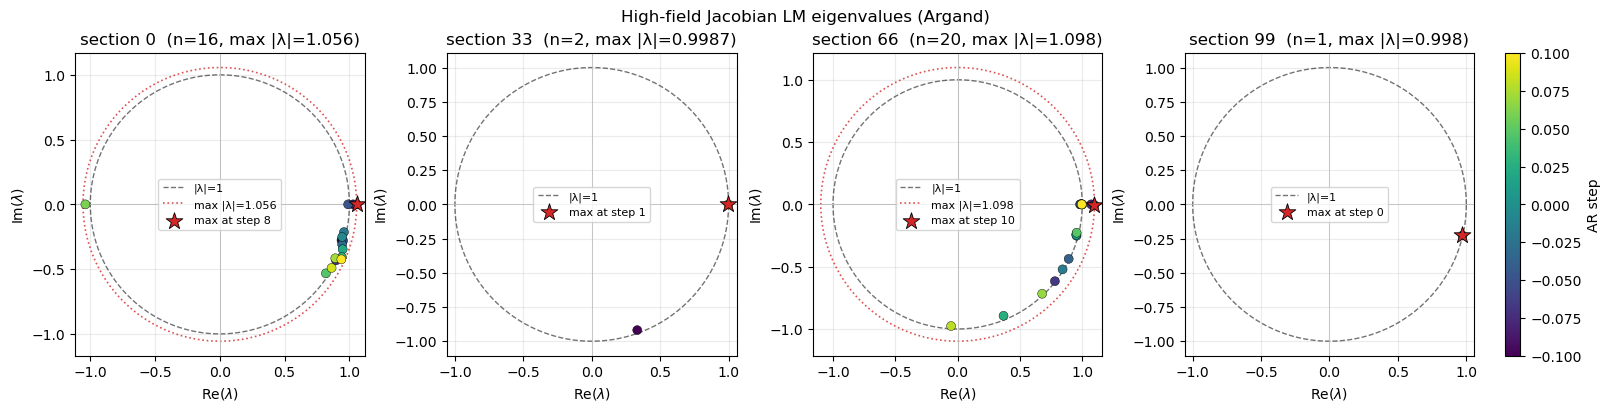

wrote /pscratch/sd/d/divyam/hine_runs/paper_1gpu/jacobian_high_eigs/scipy_3_n4/plots/argand_by_section.png


In [11]:
sids = sorted(sections)
n = len(sids)
fig, axes = plt.subplots(1, n, figsize=(4.0 * n, 4.0), constrained_layout=True)
if n == 1:
    axes = [axes]

last_sc = None
for ax, sid in zip(axes, sids):
    rows = sections[sid]
    rmax = max((r["radius"] for r in rows), default=float("nan"))
    last_sc = argand_section(
        ax, rows,
        title=f"section {sid}  (n={len(rows)}, max |λ|={rmax:.4g})",
    )

if last_sc is not None:
    cbar = fig.colorbar(last_sc, ax=axes, fraction=0.02, pad=0.02)
    cbar.set_label("AR step")

fig.suptitle("High-field Jacobian LM eigenvalues (Argand)", fontsize=12)
fig.savefig(OUT / "argand_by_section.png", dpi=150)
plt.show()
print("wrote", OUT / "argand_by_section.png")

## Time series of eigenvalue radii

`|λ|_max` at each autoregressive frame for every section. Overlay + per-section panels. Stars mark the peak radius on each series; points with `|λ|>1` are highlighted.

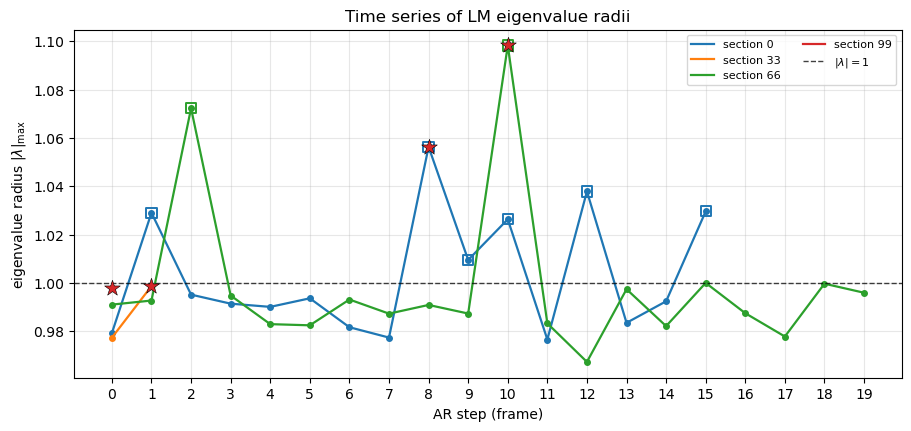

wrote /pscratch/sd/d/divyam/hine_runs/paper_1gpu/jacobian_high_eigs/scipy_3_n4/plots/radius_timeseries.png
wrote /pscratch/sd/d/divyam/hine_runs/paper_1gpu/jacobian_high_eigs/scipy_3_n4/plots/radius_vs_step.png


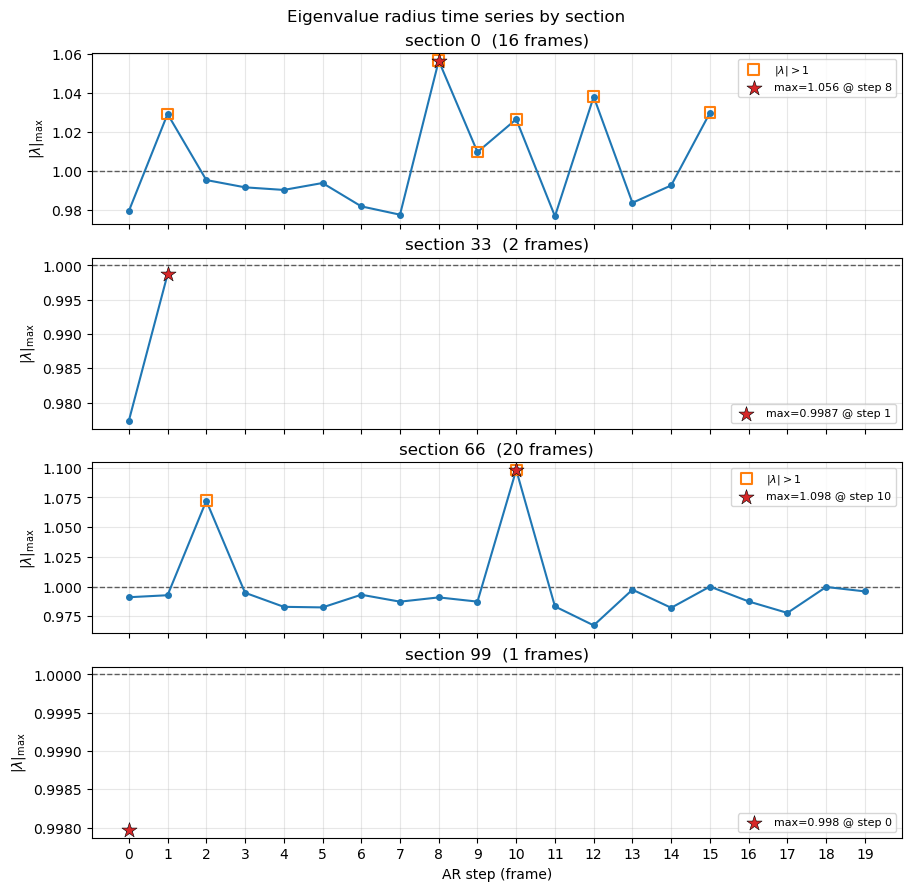

wrote /pscratch/sd/d/divyam/hine_runs/paper_1gpu/jacobian_high_eigs/scipy_3_n4/plots/radius_timeseries_by_section.png


In [12]:
# Overlay time series
fig, ax = plt.subplots(figsize=(9, 4.2), constrained_layout=True)
for sid in sids:
    rows = sections[sid]
    if not rows:
        continue
    steps = np.array([r["step"] for r in rows], dtype=int)
    radii = np.array([r["radius"] for r in rows], dtype=float)
    ax.plot(steps, radii, "-", lw=1.6, label=f"section {sid}")
    ax.plot(steps, radii, "o", ms=4, color=ax.lines[-1].get_color())
    above = radii > 1.0 + 1e-8
    if np.any(above):
        ax.scatter(
            steps[above], radii[above], s=55, marker="s",
            facecolors="none", edgecolors=ax.lines[-1].get_color(),
            linewidths=1.4, zorder=4,
        )
    imax = int(np.argmax(radii))
    ax.scatter(
        [steps[imax]], [radii[imax]], s=140, marker="*",
        c="C3", edgecolors="k", linewidths=0.4, zorder=5,
    )

ax.axhline(1.0, color="k", ls="--", lw=1.0, alpha=0.75, label=r"$|\lambda|=1$")
ax.set_xlabel("AR step (frame)")
ax.set_ylabel(r"eigenvalue radius $|\lambda|_{\max}$")
ax.set_title("Time series of LM eigenvalue radii")
ax.set_xticks(range(0, 20))
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8, ncols=2)
fig.savefig(OUT / "radius_timeseries.png", dpi=150)
fig.savefig(OUT / "radius_vs_step.png", dpi=150)
plt.show()
print("wrote", OUT / "radius_timeseries.png")
print("wrote", OUT / "radius_vs_step.png")

# Per-section panels
n = len(sids)
fig, axes = plt.subplots(n, 1, figsize=(9, 2.2 * n), sharex=True, constrained_layout=True)
if n == 1:
    axes = [axes]
for ax, sid in zip(axes, sids):
    rows = sections[sid]
    ax.axhline(1.0, color="k", ls="--", lw=1.0, alpha=0.6)
    if not rows:
        ax.set_ylabel(f"sec {sid}")
        ax.set_title(f"section {sid}: no data")
        continue
    steps = np.array([r["step"] for r in rows], dtype=int)
    radii = np.array([r["radius"] for r in rows], dtype=float)
    ax.plot(steps, radii, "o-", ms=4, lw=1.5, color="C0")
    above = radii > 1.0 + 1e-8
    if np.any(above):
        ax.scatter(
            steps[above], radii[above], s=60, marker="s",
            facecolors="none", edgecolors="C1", linewidths=1.5, zorder=4,
            label=r"$|\lambda|>1$",
        )
    imax = int(np.argmax(radii))
    ax.scatter(
        [steps[imax]], [radii[imax]], s=130, marker="*", c="C3",
        edgecolors="k", linewidths=0.4, zorder=5,
        label=f"max={radii[imax]:.4g} @ step {steps[imax]}",
    )
    ax.set_ylabel(r"$|\lambda|_{\max}$")
    ax.set_title(f"section {sid}  ({len(rows)} frames)")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc="best")
axes[-1].set_xlabel("AR step (frame)")
axes[-1].set_xticks(range(0, 20))
fig.suptitle("Eigenvalue radius time series by section", fontsize=12)
fig.savefig(OUT / "radius_timeseries_by_section.png", dpi=150)
plt.show()
print("wrote", OUT / "radius_timeseries_by_section.png")

## Combined Argand (all sections)

All LM eigenvalues from every section on one plane; marker shape encodes section.

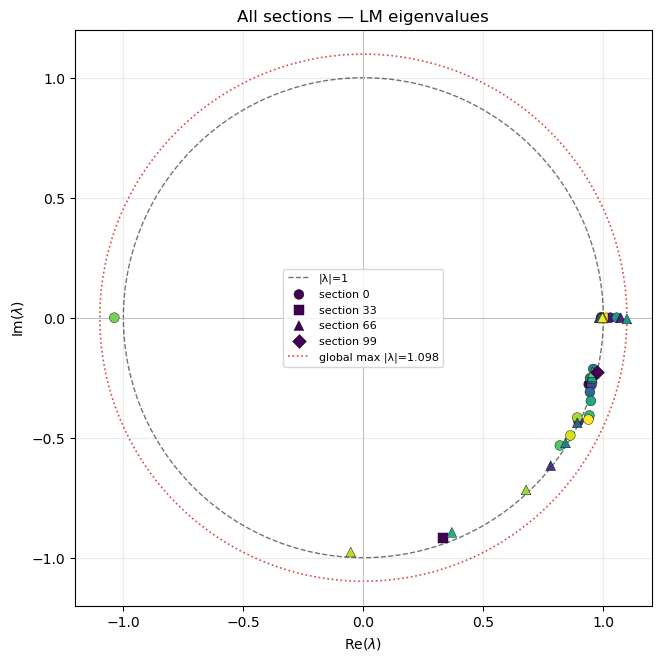

wrote /pscratch/sd/d/divyam/hine_runs/paper_1gpu/jacobian_high_eigs/scipy_3_n4/plots/argand_all_sections.png


In [13]:
markers = ["o", "s", "^", "D", "v", "P"]
fig, ax = plt.subplots(figsize=(6.5, 6.5), constrained_layout=True)
draw_unit_circle(ax, 1.0, color="k", ls="--", lw=1.0, alpha=0.55, label="|λ|=1")

all_radii = []
for i, sid in enumerate(sids):
    rows = sections[sid]
    if not rows:
        continue
    lams = np.array([r["lambda"] for r in rows])
    steps = np.array([r["step"] for r in rows])
    all_radii.extend(np.abs(lams).tolist())
    ax.scatter(
        lams.real, lams.imag, c=steps, cmap="viridis",
        marker=markers[i % len(markers)], s=50,
        edgecolors="k", linewidths=0.3,
        label=f"section {sid}", zorder=3,
    )

if all_radii:
    r_max = float(np.max(all_radii))
    if r_max > 1.0 + 1e-8:
        draw_unit_circle(
            ax, r_max, color="C3", ls=":", lw=1.2, alpha=0.85,
            label=f"global max |λ|={r_max:.4g}",
        )

ax.set_aspect("equal", adjustable="datalim")
ax.grid(True, alpha=0.25)
ax.set_xlabel(r"Re($\lambda$)")
ax.set_ylabel(r"Im($\lambda$)")
ax.set_title("All sections — LM eigenvalues")
ax.legend(fontsize=8, loc="best")
fig.savefig(OUT / "argand_all_sections.png", dpi=150)
plt.show()
print("wrote", OUT / "argand_all_sections.png")

## Summary table

In [14]:
print(f"{'section':>8} {'n_ok':>5} {'min|λ|':>10} {'max|λ|':>10} {'argmax_step':>12} {'λ_max':>28}")
for sid in sids:
    rows = sections[sid]
    if not rows:
        print(f"{sid:>8} {0:>5}")
        continue
    radii = np.array([r["radius"] for r in rows])
    imax = int(np.argmax(radii))
    lam = rows[imax]["lambda"]
    print(
        f"{sid:>8} {len(rows):>5} {radii.min():>10.6f} {radii.max():>10.6f} "
        f"{rows[imax]['step']:>12} {lam.real:>12.6f}{lam.imag:+.6f}j"
    )

 section  n_ok     min|λ|     max|λ|  argmax_step                        λ_max
       0    16   0.976580   1.056280            8     1.056280+0.000000j
      33     2   0.977345   0.998685            1     0.998685+0.000000j
      66    20   0.967316   1.098208           10     1.098195-0.005321j
      99     1   0.997968   0.997968            0     0.971717-0.227392j
